# 02 - Modelling & Validation: recursive and lag-window ARIMA forecasts
### Day-ahead forecasting of French hourly electricity demand

We forecast the next UTC day from information available at the daily cutoff. Both models are **non-seasonal ARIMA** on a
deseasonalised anomaly (season x Paris-local weekday x hour normal, learned on training data only); we forecast the anomaly
and add the normal back. They differ only in which lags drive the forecast:

1. **Recursive ARIMA:** fits ARIMA(p, 0, q) to the hourly anomaly. From the cutoff it rolls its **own predictions** forward
   across the gap and the whole delivery day; each later step uses earlier model outputs. A fresh origin each day resets to the
   actual anomalies observed by then - a small day-to-day discontinuity is expected and intentional.
2. **Lag-window ARIMA (24/48):** fits one ARIMA(p, 0, q) per hour-of-day on that hour's *daily* anomaly series, then forecasts
   each delivery hour from the most recent **observed** same-hour value - **lag 24** for hours 00-11, **lag 48** for hours
   12-23. These inputs are always real data available at the cutoff, as they would be at real forecast time, so it never feeds
   predictions back.
3. **Raw-load hybrid benchmark:** copies the observed same-hour load at those 24/48-hour source times, with no fitted model.

We grid-search **(p, q)** for both ARIMAs on the same validation dates, then compare them on identical held-out test dates.
The cutoff and UTC/DST scope are explained in Section 2.

## 0 - Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("Ready - pandas", pd.__version__)

Ready - pandas 3.0.6


In [2]:
# ---- Shared visual style (same system as notebooks 00/01) ----
PALETTE = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
           "violet": "#6250d6", "red": "#e34948", "green": "#0ca30c",
           "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9", "surface": "#fcfcfb"}
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
BLUE_CMAP = LinearSegmentedColormap.from_list("brand_blue", BLUE_RAMP)
GRADE_CMAP = LinearSegmentedColormap.from_list("brand_grade", ["#1baf7a", "#eda100", "#e34948"])  # good->bad
plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"],
    "savefig.facecolor": PALETTE["surface"], "savefig.bbox": "tight",
    "axes.edgecolor": PALETTE["muted"], "axes.linewidth": 0.8, "axes.labelcolor": PALETTE["ink2"],
    "axes.titlecolor": PALETTE["ink"], "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 10,
    "axes.labelsize": 11, "text.color": PALETTE["ink"], "xtick.color": PALETTE["muted"], "ytick.color": PALETTE["muted"],
    "xtick.labelcolor": PALETTE["ink2"], "ytick.labelcolor": PALETTE["ink2"], "axes.grid": True,
    "grid.color": PALETTE["grid"], "grid.linewidth": 0.8, "grid.alpha": 0.9, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11, "legend.frameon": False,
    "legend.fontsize": 10, "figure.dpi": 110, "lines.linewidth": 1.8})
gw_fmt  = FuncFormatter(lambda v, _: f"{v/1000:,.0f}")
gw1_fmt = FuncFormatter(lambda v, _: f"{v/1000:,.1f}")
def titled(ax, title=None, xlabel=None, ylabel=None):
    if title is not None: ax.set_title(title, loc="left")
    if xlabel is not None: ax.set_xlabel(xlabel)
    if ylabel is not None: ax.set_ylabel(ylabel)
    ax.margins(x=0.01); return ax
FIG = Path("..") / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print("Style loaded.")

Style loaded.


## 1 - Load the cleaned data and recall the split

In [3]:
df = pd.read_csv(Path("..") / "data" / "processed" / "france_clean_hourly.csv")
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"], utc=True)
df = df.set_index("datetime_utc").asfreq("h")
load = df["load_mw"]
print(f"{len(df):,} hourly rows  |  {df.index.min()} -> {df.index.max()}")
print(df["split"].value_counts().reindex(["train","val","test"]).to_string())
df[["load_mw","rte_forecast_d1_mw","temperature_c","dow","hour","split"]].head(3)

65,712 hourly rows  |  2019-01-01 00:00:00+00:00 -> 2026-06-30 23:00:00+00:00
split
train    43823
val       8784
test     13105


,load_mw,rte_forecast_d1_mw,temperature_c,dow,hour,split
datetime_utc,,,,,,
2019-01-01 00:00:00+00:00,"60,826.000","60,837.500",5.850,1,1,train
2019-01-01 01:00:00+00:00,"59,786.500","59,500.000",6.350,1,2,train
2019-01-01 02:00:00+00:00,"56,622.000","56,012.500",5.910,1,3,train


## 2 - Day-ahead protocol: which observations are available?
The experiment forecasts the next **UTC calendar day** from the last observed row at **11:00 UTC** (12:00 CET in winter).

**Pipeline 1 - recursive ARIMA:** its first forecast step is **12:00 UTC on day D**, not midnight. It forecasts 36 hourly
steps (D 12:00 through D+1 23:00); the first 12 bridge the cutoff-to-delivery gap, and the final 24 are the next-day forecast.
Each later step uses the model's preceding predictions; the next origin discards that path and re-conditions on actuals.

**Pipeline 2 - lag-window ARIMA (24/48):** it forecasts each delivery hour on that hour's own daily anomaly series, using only
values observed by the cutoff. Targets **00:00-11:00 UTC** are a one-step-ahead forecast from day D (lag 24); targets
**12:00-23:00 UTC** are a two-step-ahead forecast from day D-1 (lag 48), because the same-day values are still in the future
at the cutoff. Every input is real data available at forecast time - predictions are never fed back as inputs.

The seasonal normal (season x Paris-local weekday x hour, learned on training data only) is added back to both ARIMA
forecasts. The raw-load hybrid simply copies the observed source load.

**Time-zone scope:** target days and the 24/48-hour switch here are UTC-based. A year-round French-market implementation
should define the cutoff and delivery day in Europe/Paris and handle 23/25-hour daylight-saving days.

In [4]:
# Verify source timestamps against the day-ahead cutoff on a winter UTC day.
verification_targets = pd.date_range("2025-01-08 00:00", periods=24, freq="h", tz="UTC")
verification_lags = np.where(verification_targets.hour < 12, 24, 48)
verification_sources = verification_targets - pd.to_timedelta(verification_lags, unit="h")
verification_cutoff = verification_targets[0] - pd.Timedelta(hours=13)  # D 11:00 UTC

check = pd.DataFrame({
    "target_utc": verification_targets,
    "lag_hours": verification_lags,
    "source_utc": verification_sources,
})
check["available_by_cutoff"] = check["source_utc"] <= verification_cutoff
check["source_value_exists"] = load.reindex(verification_sources).notna().to_numpy()
print("Cutoff:", verification_cutoff)
print("All lag sources are observed by the cutoff:", bool(check["available_by_cutoff"].all()))
print("All source load values exist:", bool(check["source_value_exists"].all()))
assert check["available_by_cutoff"].all()
assert check["source_value_exists"].all()
check

Cutoff: 2025-01-07 11:00:00+00:00
All lag sources are observed by the cutoff: True
All source load values exist: True


,target_utc,lag_hours,source_utc,available_by_cutoff,source_value_exists
0,2025-01-08 00:00:00+00:00,24,2025-01-07 00:00:00+00:00,True,True
1,2025-01-08 01:00:00+00:00,24,2025-01-07 01:00:00+00:00,True,True
2,2025-01-08 02:00:00+00:00,24,2025-01-07 02:00:00+00:00,True,True
3,2025-01-08 03:00:00+00:00,24,2025-01-07 03:00:00+00:00,True,True
4,2025-01-08 04:00:00+00:00,24,2025-01-07 04:00:00+00:00,True,True
5,2025-01-08 05:00:00+00:00,24,2025-01-07 05:00:00+00:00,True,True
6,2025-01-08 06:00:00+00:00,24,2025-01-07 06:00:00+00:00,True,True
7,2025-01-08 07:00:00+00:00,24,2025-01-07 07:00:00+00:00,True,True
8,2025-01-08 08:00:00+00:00,24,2025-01-07 08:00:00+00:00,True,True
9,2025-01-08 09:00:00+00:00,24,2025-01-07 09:00:00+00:00,True,True


## 3 - Deseasonalise: the "normal + anomaly" (TP02)
A seasonal ARIMA on 65k hourly points is costly, so we first remove a calendar baseline. For each **season, weekday, and hour**,
we calculate the mean load using **training data only** (up to 672 baseline values). The **anomaly** is actual load minus this
season-specific normal. We model the anomaly with a non-seasonal ARIMA, then rebuild load = forecast anomaly + normal.

normal profile: 672 (season x weekday x hour) values
anomaly: mean -461.6 MW, std 6,051 MW


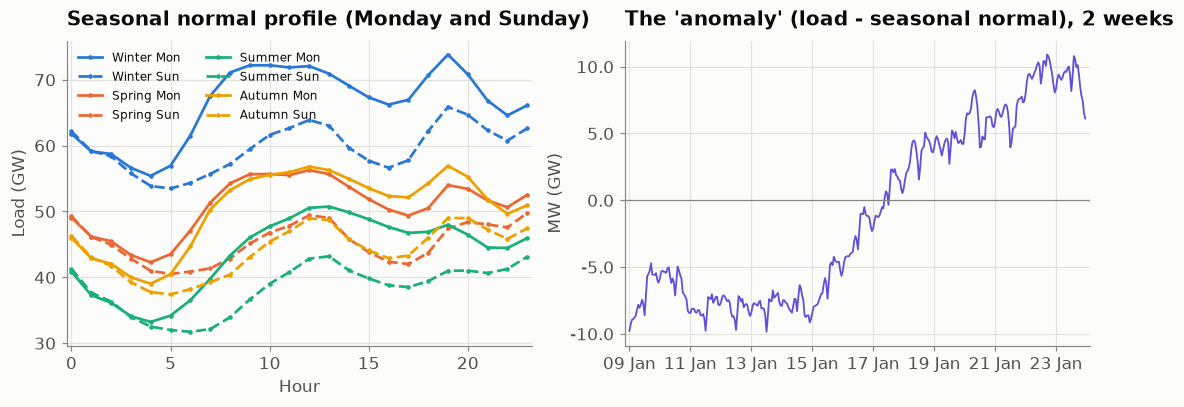

In [5]:
train = df[df["split"] == "train"]
normal_tbl = train.groupby(["season", "dow", "hour"])["load_mw"].mean()
normal = pd.Series(
    pd.MultiIndex.from_arrays([df["season"], df["dow"], df["hour"]]).map(normal_tbl),
    index=df.index,
    name="normal",
)
anomaly = (load - normal).rename("anomaly").asfreq("h")
print("normal profile:", normal_tbl.shape[0], "(season x weekday x hour) values")
print(f"anomaly: mean {anomaly.mean():+.1f} MW, std {anomaly.std():,.0f} MW")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
season_colors = {
    "Winter": PALETTE["blue"],
    "Spring": PALETTE["orange"],
    "Summer": PALETTE["aqua"],
    "Autumn": PALETTE["yellow"],
}
for season, color in season_colors.items():
    for day, label, linestyle in [(0, "Mon", "-"), (6, "Sun", "--")]:
        profile = normal_tbl.loc[(season, day)]
        ax[0].plot(
            profile.index,
            profile.values,
            color=color,
            linestyle=linestyle,
            marker="o",
            ms=2,
            label=f"{season} {label}",
        )
ax[0].yaxis.set_major_formatter(gw_fmt)
ax[0].legend(ncol=2, fontsize=8)
titled(ax[0], "Seasonal normal profile (Monday and Sunday)", xlabel="Hour", ylabel="Load (GW)")
ax[1].plot(anomaly.loc["2023-01-09":"2023-01-23"].index, anomaly.loc["2023-01-09":"2023-01-23"].values,
           color=PALETTE["violet"], lw=1.2)
ax[1].axhline(0, color=PALETTE["muted"], lw=0.8)
ax[1].yaxis.set_major_formatter(gw1_fmt)
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
titled(ax[1], "The 'anomaly' (load - seasonal normal), 2 weeks", ylabel="MW (GW)")
fig.savefig(FIG / "20_normal_anomaly.png"); plt.show()

In [6]:
# Is the anomaly stationary? (ADF H0: unit root ; KPSS H0: stationary)
a = anomaly.dropna().iloc[-20000:]
adf = adfuller(a, autolag="AIC"); kp = kpss(a, regression="c", nlags="auto")
print(f"ADF  stat {adf[0]:.2f}  p {adf[1]:.4f}  -> {'stationary' if adf[1]<0.05 else 'unit root'}")
print(f"KPSS stat {kp[0]:.3f}  p {kp[1]:.4f}  -> {'stationary' if kp[1]>0.05 else 'non-stationary'}")
print("\n-> On the most recent 20,000 hours, ADF rejects a unit root and KPSS does not reject stationarity.")
print("   This supports d = 0 for that window; slower regime or weather shifts may still remain elsewhere.")

ADF  stat -6.03  p 0.0000  -> stationary
KPSS stat 0.186  p 0.1000  -> stationary

-> On the most recent 20,000 hours, ADF rejects a unit root and KPSS does not reject stationarity.
   This supports d = 0 for that window; slower regime or weather shifts may still remain elsewhere.


C:\Users\marouane.housni\AppData\Local\Temp\ipykernel_2376\2965681514.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  adf = adfuller(a, autolag="AIC"); kp = kpss(a, regression="c", nlags="auto")


### Identify candidate orders (ACF / PACF of the anomaly)

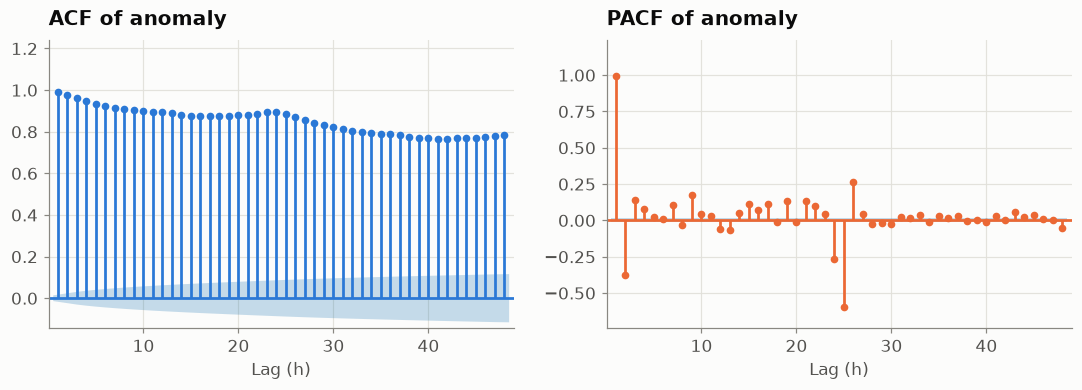

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
plot_acf(a, lags=48, ax=ax[0], zero=False, auto_ylims=True, title=None,
         color=PALETTE["blue"], markersize=4, vlines_kwargs={"colors": PALETTE["blue"]})
plot_pacf(a, lags=48, ax=ax[1], zero=False, auto_ylims=True, method="ywm", title=None,
          color=PALETTE["orange"], markersize=4, vlines_kwargs={"colors": PALETTE["orange"]})
titled(ax[0], "ACF of anomaly", xlabel="Lag (h)"); titled(ax[1], "PACF of anomaly", xlabel="Lag (h)")
fig.savefig(FIG / "21_anomaly_acf_pacf.png"); plt.show()

## 4 - Two ARIMA pipelines and a raw-lag benchmark
- **Recursive ARIMA:** fits p/q dynamics to the hourly anomaly; forecasts from the cutoff through the 12-hour bridge and all 24 delivery hours, feeding its own predictions forward. A fresh origin each day resets to the latest actuals.
- **Lag-window ARIMA (24/48):** one ARIMA(p, 0, q) per hour-of-day, fit on that hour's daily anomaly series. It forecasts each delivery hour from the observed lag-24/48 same-hour value (1-step-ahead for hours 00-11, 2-step-ahead for 12-23), never recycling its own output.
- **Raw-lag hybrid:** copies the observed load at lag 24 or 48, with no fitted model.

Both ARIMA pipelines add back the same training-only seasonal normal. The lag-window ARIMA tests whether learning same-hour
dynamics on the 24/48 window improves on simple copying; the raw-lag hybrid shows the value added by fitting that mapping.

In [8]:
H_GAP = 13          # UTC hours from the 11:00 cutoff to D+1 00:00
STEPS = 36          # recursive ARIMA bridge plus the 24 target hours
TRAIL = 1500        # trailing window of hourly anomaly used to condition recursive ARIMA
TRAIL_D = 400       # trailing window of daily anomaly used to condition the lag-window ARIMA

# The "24/48 window" lives in 24 same-hour daily series: for each hour-of-day h, HOUR_SERIES[h]
# is the anomaly at that hour indexed by calendar day. A lag-24 input is the previous day's value
# in that series; a lag-48 input is two days back. These are the inputs available at the cutoff.
HOUR_SERIES = {}
for _h in range(24):
    _s = anomaly[anomaly.index.hour == _h]
    HOUR_SERIES[_h] = pd.Series(_s.to_numpy(), index=_s.index.normalize()).asfreq("D")


def target_index(dplus1_date):
    t0 = pd.Timestamp(dplus1_date)
    if t0.tz is None:
        t0 = t0.tz_localize("UTC")
    return pd.date_range(t0, periods=24, freq="h")


def forecast_recursive(res, dplus1_date):
    # Recursive ARIMA: conditioned on the REAL anomaly up to the cutoff, it rolls its own
    # predictions forward across the 36-step horizon. A fresh origin each day resets to actuals,
    # so adjacent daily forecasts can jump - intentional, matching each real issue time.
    tgt = target_index(dplus1_date)
    cutoff = tgt[0] - pd.Timedelta(hours=H_GAP)
    hist = anomaly.loc[:cutoff].iloc[-TRAIL:].asfreq("h")
    fc = res.apply(hist, refit=False).get_forecast(STEPS).predicted_mean
    return (fc.reindex(tgt) + normal.reindex(tgt)).rename("recursive")


def build_lag_window_arima(fit_start, fit_end, order):
    # One ARIMA(p, 0, q) per hour-of-day, fit on that hour's daily anomaly series.
    models = {}
    for h in range(24):
        series = HOUR_SERIES[h].loc[fit_start:fit_end].asfreq("D")
        models[h] = ARIMA(series, order=order, trend="n").fit()
    return models


def forecast_lag_window(models, dplus1_date):
    # "Direct" lag-window ARIMA: each delivery hour is forecast on its own daily series from values
    # observed by the cutoff. Hours 00-11 -> 1-step-ahead from day D (lag 24); hours 12-23 ->
    # 2-step-ahead from day D-1 (lag 48). Inputs are always real data, as at forecast time.
    tgt = target_index(dplus1_date)
    out = np.empty(24)
    for i, ts in enumerate(tgt):
        h = ts.hour
        steps = 1 if h < 12 else 2
        cond_end = ts.normalize() - pd.Timedelta(days=steps)
        hist = HOUR_SERIES[h].loc[:cond_end].iloc[-TRAIL_D:].asfreq("D")
        out[i] = models[h].apply(hist, refit=False).get_forecast(steps).predicted_mean.iloc[-1]
    return pd.Series(out, index=tgt, name="direct_lag") + normal.reindex(tgt)


def forecast_hybrid(dplus1_date):
    tgt = target_index(dplus1_date)
    lag_hours = np.where(tgt.hour < 12, 24, 48)
    sources = tgt - pd.to_timedelta(lag_hours, unit="h")
    cutoff = tgt[0] - pd.Timedelta(hours=H_GAP)
    if (sources > cutoff).any():
        raise ValueError("Hybrid forecast would use a load value unavailable at the cutoff.")
    source_load = load.reindex(sources)
    if source_load.isna().any():
        raise ValueError("Hybrid forecast source load is missing for one or more target hours.")
    return pd.Series(source_load.to_numpy(), index=tgt, name="hybrid")


def actuals(dplus1_date):
    tgt = target_index(dplus1_date)
    return load.reindex(tgt), df["rte_forecast_d1_mw"].reindex(tgt)


print("Forecasting engine ready: recursive ARIMA, lag-window (24/48) ARIMA, and raw-lag hybrid.")

Forecasting engine ready: recursive ARIMA, lag-window (24/48) ARIMA, and raw-lag hybrid.


## 5 - Grid-search (p, q) for both ARIMA pipelines on the same validation dates
Pipeline 1 tunes ARIMA (p, q) on the hourly anomaly, scored by **recursive** day-ahead MAE. Pipeline 2 tunes a single
ARIMA (p, q) shared by the 24 per-hour lag-window models, scored by its **real-input** day-ahead MAE. Both use the same
train-only fitting window (2023) and the same 14 day-ahead validation origins. Lowest validation MAE is selected for each.

In [9]:
def backtest_recursive_mae(model, dates):
    errors = []
    for date in dates:
        forecast = forecast_recursive(model, date)
        actual, _ = actuals(date)
        errors.append((actual - forecast).abs())
    return pd.concat(errors).mean()


def backtest_lag_window_mae(models, dates):
    errors = []
    for date in dates:
        forecast = forecast_lag_window(models, date)
        actual, _ = actuals(date)
        errors.append((actual - forecast).abs())
    return pd.concat(errors).mean()


GRID_FIT_START, GRID_FIT_END = "2023-01-01", "2023-12-31"
GRID_FIT = anomaly.loc[GRID_FIT_START:GRID_FIT_END]
VAL_DATES = pd.date_range("2024-01-09", periods=14, freq="D", tz="UTC")
P_RANGE, Q_RANGE = range(0, 4), range(0, 4)

# Pipeline 1 - recursive ARIMA on the hourly anomaly.
recursive_records = []
for p, q in itertools.product(P_RANGE, Q_RANGE):
    if p == 0 and q == 0:
        continue
    model = ARIMA(GRID_FIT, order=(p, 0, q), trend="n").fit()
    recursive_records.append({
        "p": p,
        "q": q,
        "val_MAE": backtest_recursive_mae(model, VAL_DATES),
        "AIC": model.aic,
    })
recursive_grid = pd.DataFrame(recursive_records).sort_values("val_MAE").reset_index(drop=True)
best_p = int(recursive_grid.iloc[0]["p"])
best_q = int(recursive_grid.iloc[0]["q"])
print("Pipeline 1 - recursive ARIMA, top 5 by validation MAE:")
print(recursive_grid.head(5).to_string(index=False))
print(f"Selected ARIMA({best_p}, 0, {best_q}): {recursive_grid.iloc[0]['val_MAE']:,.0f} MW validation MAE")

# Pipeline 2 - lag-window ARIMA: one shared (p, q) across the 24 per-hour daily models.
lag_records = []
for p, q in itertools.product(P_RANGE, Q_RANGE):
    if p == 0 and q == 0:
        continue
    models = build_lag_window_arima(GRID_FIT_START, GRID_FIT_END, (p, 0, q))
    lag_records.append({
        "p": p,
        "q": q,
        "val_MAE": backtest_lag_window_mae(models, VAL_DATES),
    })
lag_grid = pd.DataFrame(lag_records).sort_values("val_MAE").reset_index(drop=True)
best_lp = int(lag_grid.iloc[0]["p"])
best_lq = int(lag_grid.iloc[0]["q"])
print("\nPipeline 2 - lag-window ARIMA (24/48), top 5 by validation MAE:")
print(lag_grid.head(5).to_string(index=False))
print(f"Selected lag-window ARIMA({best_lp}, 0, {best_lq}): {lag_grid.iloc[0]['val_MAE']:,.0f} MW validation MAE")

C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Pipeline 1 - recursive ARIMA, top 5 by validation MAE:
 p  q   val_MAE         AIC
 1  0 3,189.078 139,706.037
 3  1 3,309.715 137,756.069
 3  0 3,315.767 137,758.405
 1  3 3,348.583 137,782.984
 3  2 3,403.178 137,586.281
Selected ARIMA(1, 0, 0): 3,189 MW validation MAE


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_par

C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_par

... (33 outputs left out)

C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params



Pipeline 2 - lag-window ARIMA (24/48), top 5 by validation MAE:
 p  q   val_MAE
 3  2 3,602.235
 3  3 3,621.293
 2  3 3,696.677
 1  1 3,709.321
 2  1 3,713.847
Selected lag-window ARIMA(3, 0, 2): 3,602 MW validation MAE


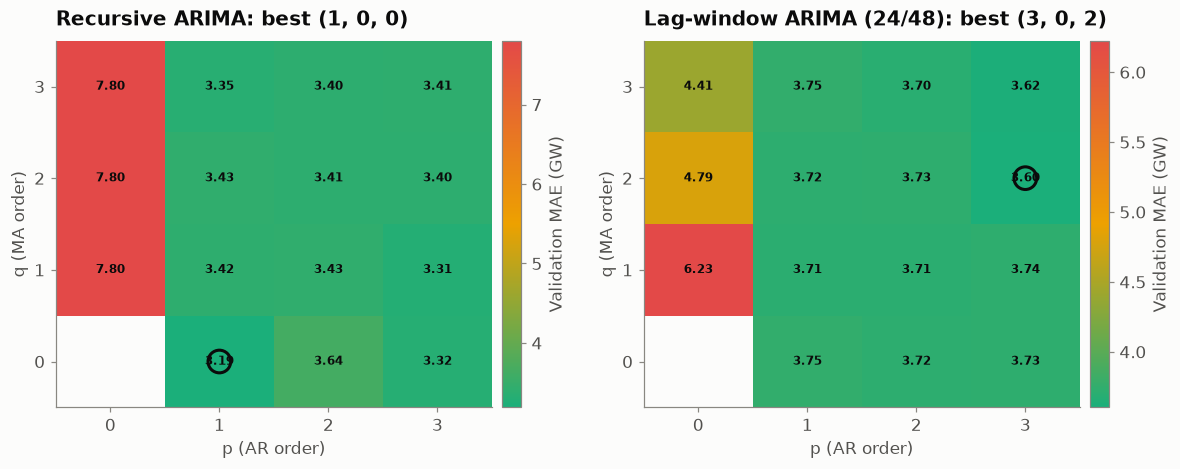

In [10]:
# Validation tuning: (p, q) grids for both ARIMA pipelines.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
panels = [
    (axes[0], recursive_grid, best_p, best_q, f"Recursive ARIMA: best ({best_p}, 0, {best_q})"),
    (axes[1], lag_grid, best_lp, best_lq, f"Lag-window ARIMA (24/48): best ({best_lp}, 0, {best_lq})"),
]
for ax, grid, bp, bq, title in panels:
    pivot = grid.pivot(index="q", columns="p", values="val_MAE")
    heatmap = ax.imshow(pivot.values / 1000, origin="lower", cmap=GRADE_CMAP, aspect="auto")
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
    ax.grid(False)
    for row in range(pivot.shape[0]):
        for column in range(pivot.shape[1]):
            value = pivot.values[row, column]
            if np.isfinite(value):
                ax.text(column, row, f"{value / 1000:.2f}", ha="center", va="center", fontsize=8,
                        color=PALETTE["ink"], fontweight="bold")
    ax.scatter([bp], [bq], s=220, facecolors="none", edgecolors=PALETTE["ink"], linewidths=2)
    fig.colorbar(heatmap, ax=ax, pad=0.02).set_label("Validation MAE (GW)", color=PALETTE["ink2"])
    titled(ax, title, xlabel="p (AR order)", ylabel="q (MA order)")
fig.tight_layout()
fig.savefig(FIG / "22_model_tuning_comparison.png")
plt.show()

**Validation results.** Recursive ARIMA selects **ARIMA(1, 0, 0)** at **3.19 GW MAE**; its pure-MA orders (p = 0) are
far worse (~8 GW - with no AR term the forecast reverts to the mean over the long recursive horizon). The lag-window ARIMA
selects **ARIMA(3, 0, 2)** at **3.60 GW MAE** on the same 14 validation origins: forecasting each hour from the real 24/48
lag needs a richer (p, q) than the recursive model, yet lands only ~0.4 GW behind it despite never feeding predictions back.

## 6 - Numerical comparison on the held-out test period
This is a rolling day-ahead evaluation with a **fresh origin each day**. Recursive ARIMA uses its own predictions only within
the current 36-step forecast (12 bridge hours plus the next 24-hour delivery day). At the next origin, it discards that path
and conditions again on actual anomalies observed through the new cutoff. This can create a jump between adjacent daily
forecasts, which is intentional: it reflects the information available at each real forecast issue time.

The lag-window ARIMA forecasts that day's 24 targets from the real lag-24/48 same-hour values available at the cutoff (a
1-step-ahead forecast for hours 00-11, a 2-step-ahead forecast for 12-23); the next origin reads the newly observed actuals
for its own inputs. Refit both ARIMAs with their selected orders on data through 2024, then evaluate them, the raw-load
hybrid, and RTE on the same 56 rolling UTC day-ahead targets. Report MAE, RMSE, and MAPE, with paired daily-error tests.

In [11]:
FINAL_FIT_START, FINAL_FIT_END = "2021-01-01", "2024-12-31"
FINAL_FIT = anomaly.loc[FINAL_FIT_START:FINAL_FIT_END]
res_best = ARIMA(FINAL_FIT, order=(best_p, 0, best_q), trend="n").fit()
lag_models = build_lag_window_arima(FINAL_FIT_START, FINAL_FIT_END, (best_lp, 0, best_lq))

TEST_DATES = pd.date_range("2025-01-07", periods=56, freq="D", tz="UTC")
per_day = []
collect = {"recursive": [], "direct_lag": [], "hybrid": [], "rte": [], "actual": [], "hour": []}
# Each date is a fresh rolling origin. The recursive ARIMA resets to the actual anomalies observed
# by its cutoff; the lag-window ARIMA reads real lag-24/48 inputs available at that same cutoff.
for date in TEST_DATES:
    y, rte = actuals(date)
    recursive = forecast_recursive(res_best, date)
    direct_lag = forecast_lag_window(lag_models, date)
    hybrid = forecast_hybrid(date)
    per_day.append({
        "date": date,
        "recursive": (y - recursive).abs().mean(),
        "direct_lag": (y - direct_lag).abs().mean(),
        "hybrid": (y - hybrid).abs().mean(),
        "rte": (y - rte).abs().mean(),
    })
    for name, values in [
        ("recursive", recursive),
        ("direct_lag", direct_lag),
        ("hybrid", hybrid),
        ("rte", rte),
        ("actual", y),
    ]:
        collect[name].append(values.to_numpy())
    collect["hour"].append(y.index.hour)

per_day = pd.DataFrame(per_day).set_index("date")
A = {name: np.concatenate(values) for name, values in collect.items()}

def score(y, yhat):
    error = y - yhat
    return pd.Series({
        "MAE_MW": np.abs(error).mean(),
        "RMSE_MW": np.sqrt((error ** 2).mean()),
        "MAPE_%": np.abs(error / y).mean() * 100,
    })

tbl = pd.DataFrame({
    "Recursive ARIMA": score(A["actual"], A["recursive"]),
    "Lag-window ARIMA (24/48)": score(A["actual"], A["direct_lag"]),
    "Raw-load hybrid": score(A["actual"], A["hybrid"]),
    "RTE forecast": score(A["actual"], A["rte"]),
}).T
print(f"Day-ahead accuracy on the test period ({len(TEST_DATES)} days):")
print(tbl.round(1).to_string())

C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


... (3 outputs left out)

C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\marouane.housni\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Day-ahead accuracy on the test period (56 days):
                            MAE_MW   RMSE_MW  MAPE_%
Recursive ARIMA          2,513.400 3,581.600   4.000
Lag-window ARIMA (24/48) 2,635.100 3,770.100   4.200
Raw-load hybrid          3,633.600 4,737.400   5.700
RTE forecast             1,373.300 1,714.400   2.100


In [12]:
# Paired Wilcoxon tests on daily MAE differences.
w_recursive_direct = stats.wilcoxon(per_day["recursive"], per_day["direct_lag"])
w_direct_hybrid = stats.wilcoxon(per_day["direct_lag"], per_day["hybrid"])
print("Mean daily MAE (MW):")
print(per_day[["recursive", "direct_lag", "hybrid"]].mean().round(1).to_string())
print("\nRecursive ARIMA vs lag-window ARIMA (24/48):")
print(f"Wilcoxon signed-rank (H0: paired difference centered at zero): p = {w_recursive_direct.pvalue:.2e}")
print("Lag-window ARIMA (24/48) vs raw-load hybrid:")
print(f"Wilcoxon signed-rank (H0: paired difference centered at zero): p = {w_direct_hybrid.pvalue:.2e}")

Mean daily MAE (MW):
recursive    2,513.400
direct_lag   2,635.100
hybrid       3,633.600

Recursive ARIMA vs lag-window ARIMA (24/48):
Wilcoxon signed-rank (H0: paired difference centered at zero): p = 6.36e-01
Lag-window ARIMA (24/48) vs raw-load hybrid:
Wilcoxon signed-rank (H0: paired difference centered at zero): p = 1.10e-04


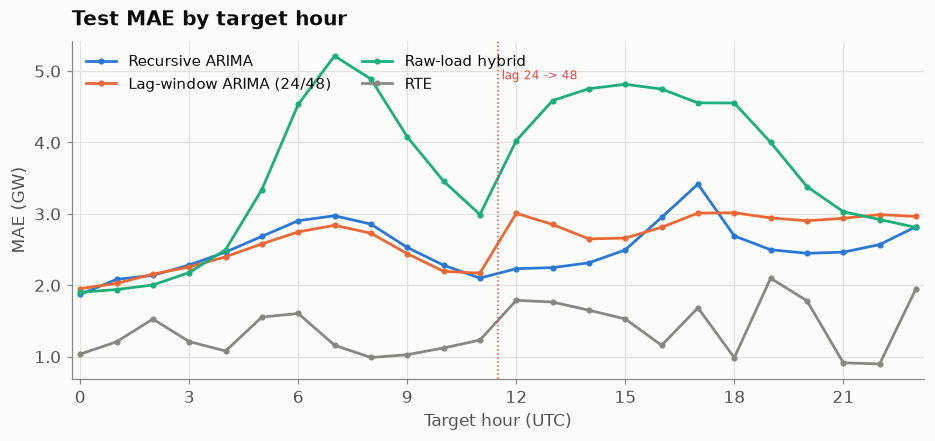

In [13]:
# Per-horizon error: recursive ARIMA, lag-window ARIMA, the raw-copy benchmark, and RTE.
hz = pd.DataFrame({
    "hour": A["hour"],
    "recursive": np.abs(A["actual"] - A["recursive"]),
    "direct_lag": np.abs(A["actual"] - A["direct_lag"]),
    "hybrid": np.abs(A["actual"] - A["hybrid"]),
    "rte": np.abs(A["actual"] - A["rte"]),
})
mh = hz.groupby("hour")[["recursive", "direct_lag", "hybrid", "rte"]].mean()
fig, ax = plt.subplots(figsize=(10, 4))
for column, color, label in [
    ("recursive", PALETTE["blue"], "Recursive ARIMA"),
    ("direct_lag", PALETTE["orange"], "Lag-window ARIMA (24/48)"),
    ("hybrid", PALETTE["aqua"], "Raw-load hybrid"),
    ("rte", PALETTE["muted"], "RTE"),
]:
    ax.plot(mh.index, mh[column], color=color, marker="o", ms=3, label=label)
ax.axvline(11.5, color=PALETTE["red"], ls=":", lw=1)
ax.text(11.6, ax.get_ylim()[1] * 0.9, "lag 24 -> 48", color=PALETTE["red"], fontsize=8)
ax.yaxis.set_major_formatter(gw1_fmt)
ax.set_xticks(range(0, 24, 3))
ax.legend(ncol=2)
titled(ax, "Test MAE by target hour", xlabel="Target hour (UTC)", ylabel="MAE (GW)")
fig.savefig(FIG / "23_per_horizon.png"); plt.show()

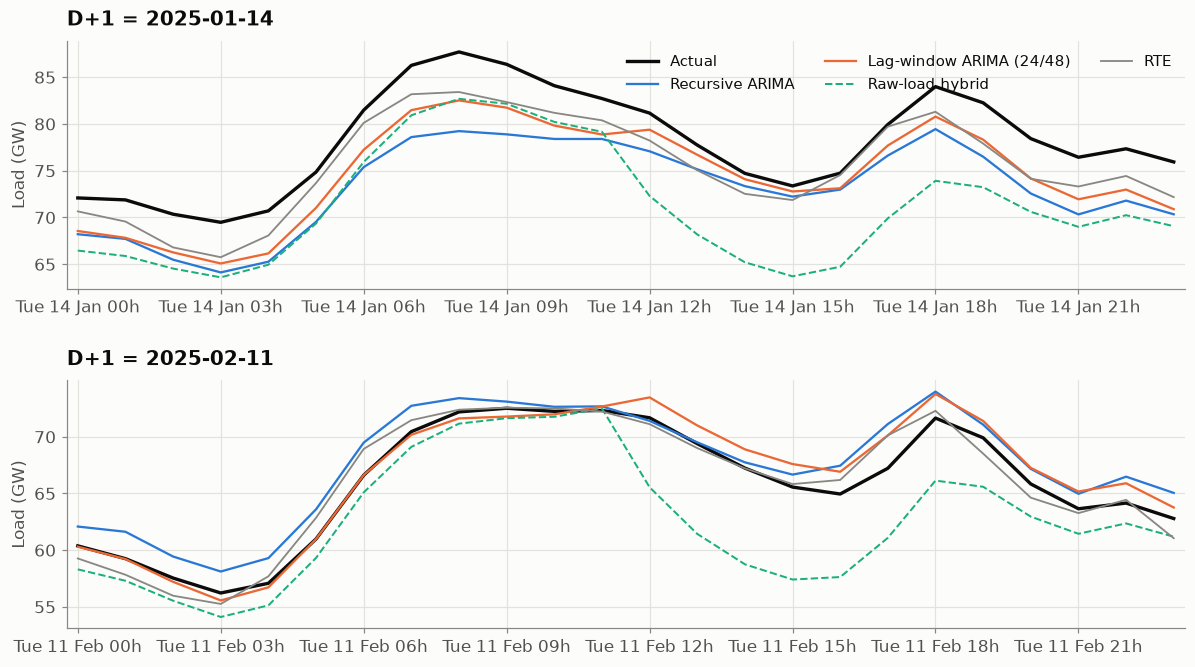

In [14]:
# Example days: compare every forecast against the same realized load.
example_dates = [TEST_DATES[7], TEST_DATES[35]]
fig, axes = plt.subplots(2, 1, figsize=(11, 6.2))
for ax, date in zip(axes, example_dates):
    y, rte = actuals(date)
    recursive = forecast_recursive(res_best, date)
    direct_lag = forecast_lag_window(lag_models, date)
    hybrid = forecast_hybrid(date)
    ax.plot(y.index, y.values, color=PALETTE["ink"], lw=2.2, label="Actual")
    ax.plot(recursive.index, recursive.values, color=PALETTE["blue"], lw=1.5, label="Recursive ARIMA")
    ax.plot(direct_lag.index, direct_lag.values, color=PALETTE["orange"], lw=1.5, label="Lag-window ARIMA (24/48)")
    ax.plot(hybrid.index, hybrid.values, color=PALETTE["aqua"], lw=1.3, ls="--", label="Raw-load hybrid")
    ax.plot(rte.index, rte.values, color=PALETTE["muted"], lw=1.2, label="RTE")
    ax.yaxis.set_major_formatter(gw_fmt)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b %Hh"))
    titled(ax, f"D+1 = {pd.Timestamp(date).date()}", ylabel="Load (GW)")
axes[0].legend(loc="upper right", ncol=3)
fig.tight_layout(h_pad=2.0)
fig.savefig(FIG / "24_example_days.png")
plt.show()

**Test-period comparison.** Across the same 56 UTC days, MAE is **2.51 GW** for recursive ARIMA, **2.64 GW** for the
lag-window ARIMA (24/48), **3.63 GW** for raw-load copying, and **1.37 GW** for RTE. The paired Wilcoxon test finds **no
significant difference** between the two ARIMAs (p = 0.64) - using only the real 24/48 lag costs almost nothing versus rolling
predictions forward. The lag-window ARIMA clearly beats raw-load copying (p = 1.1e-04), so fitting the same-hour dynamics adds
real value over simple persistence. Both fitted ARIMAs still trail RTE on this test set.

## 7 - Residual diagnostics of the chosen model

Chosen model: ARIMA(1, 0, 0)  on the anomaly
Ljung-Box on residuals (H0: no autocorrelation):
        lb_stat  lb_pvalue
24   30,270.552      0.000
168 146,191.137      0.000

-> remaining autocorrelation at 24h/168h confirms a seasonal (SARIMA) term would help next; the anomaly step removed the bulk of it, not all.


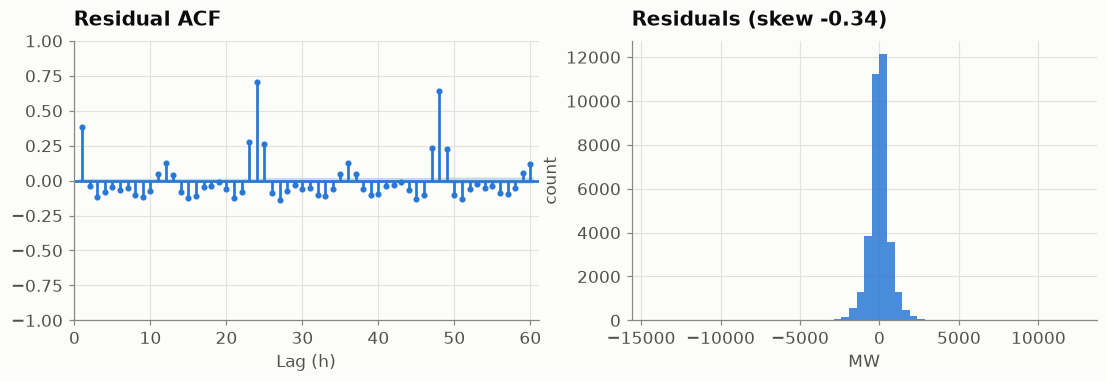

In [15]:
resid = res_best.resid.iloc[STEPS:]
lb = acorr_ljungbox(resid, lags=[24, 168], return_df=True)
print(f"Chosen model: ARIMA({best_p}, 0, {best_q})  on the anomaly")
print("Ljung-Box on residuals (H0: no autocorrelation):"); print(lb.to_string())
print("\n-> remaining autocorrelation at 24h/168h confirms a seasonal (SARIMA) term would help next;",
      "the anomaly step removed the bulk of it, not all.")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
plot_acf(resid, lags=60, ax=ax[0], zero=False, title=None, color=PALETTE["blue"],
         markersize=3, vlines_kwargs={"colors": PALETTE["blue"]})
titled(ax[0], "Residual ACF", xlabel="Lag (h)")
ax[1].hist(resid, bins=60, color=PALETTE["blue"], alpha=0.85)
titled(ax[1], f"Residuals (skew {stats.skew(resid):+.2f})", xlabel="MW", ylabel="count")
fig.savefig(FIG / "25_residuals.png"); plt.show()

## 8 - Summary

**Forecast protocol.** At the 11:00 UTC cutoff, forecast the next 24 UTC hours. Hours 00-11 have an observed same-hour value at
lag 24; hours 12-23 at lag 48. **Recursive ARIMA** rolls its own predictions forward from the cutoff and resets to actuals each
day (a small day-to-day discontinuity is expected); the **lag-window ARIMA** forecasts each hour from its real lag-24/48 value
(1-/2-step-ahead), so its inputs are always observed; the **raw-load hybrid** simply copies that lagged load.

**Seasonal normal.** Both ARIMA pipelines use the training-only mean by **season x Paris-local weekday x hour** and add that
normal back to the predicted anomaly.

**Tuning.** A brute-force **(p, q) grid scored by validation MAE** selects recursive **ARIMA(1,0,0)** (3.19 GW) and lag-window
**ARIMA(3,0,2)** (3.60 GW) on the same 14 validation origins. For the recursive model, pure-MA orders (p = 0) collapse to ~8 GW
day-ahead.

**Test comparison (56 UTC days).** MAE is recursive ARIMA **2.51 GW**, lag-window ARIMA **2.64 GW**, raw-load hybrid **3.63 GW**,
and RTE **1.37 GW**. Paired Wilcoxon p = **0.64** for recursive vs lag-window (not significant) and p = **1.1e-04** for
lag-window vs raw-copy hybrid. Both fitted ARIMAs remain behind RTE - the gap is the weather, added in Notebook 3. This is a
UTC-based backtest; a production French-market evaluation needs Paris-local cutoff logic and explicit handling of 23/25-hour
DST days.